# 0. download dataset

In [3]:
!pip install -q kagglehub[pandas-datasets]
import os
import kagglehub

path = kagglehub.dataset_download("salihacur/diabetes")
print(path)
print(os.listdir(path))

100%|██████████| 8.91k/8.91k [00:00<00:00, 8.71MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/salihacur/diabetes/versions/2
['diabetes.csv']


In [5]:
import pandas as pd

df = pd.read_csv(os.path.join(path, "diabetes.csv"))
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Task 1 — Prepare a fair experiment
- *Scenario:* A screening research team wants to compare two simple linear classification algorithms on the same data.
- Load `diabetes.csv`, inspect class balance and missing/invalid values, and choose exactly two numeric predictor columns (e.g., Glucose and BMI) so that decision boundaries can be plotted.
- Use stratified 80/20 train/test splitting with `random_state=42`.
- Impute missing values using training-only statistics if needed and standardize using training data only.
- Explain why leakage would invalidate the comparison.

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ---------- 1. Inspect ----------
print("Shape:", df.shape)
print("\nNaN per column:\n", df.isna().sum())
print("\nClass ratio:\n", df["Outcome"].value_counts(normalize=True).round(3))

zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nInvalid zeros per column:\n", (df[zero_cols] == 0).sum())

# ---------- 2. Choose two predictors ----------
features = ["Glucose", "BMI"]
X = df[features].replace(0, np.nan)   # zeros -> missing
y = df["Outcome"]

# ---------- 3. Stratified 80/20 split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("\nTrain class ratio:", round(y_train.mean(), 3))
print("Test class ratio: ", round(y_test.mean(), 3))

# ---------- 4. Impute (train median only) ----------
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# ---------- 5. Standardize (train mean/std only) ----------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)

# ---------- 6. Check ----------
print("\nTrain mean:", X_train_s.mean(axis=0).round(3))
print("Train std: ", X_train_s.std(axis=0).round(3))
print("NaN left:  ", np.isnan(X_train_s).sum() + np.isnan(X_test_s).sum())

Shape: (768, 9)

NaN per column:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class ratio:
 Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Invalid zeros per column:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Train class ratio: 0.349
Test class ratio:  0.351

Train mean: [-0.  0.]
Train std:  [1. 1.]
NaN left:   0


**Why leakage invalidates the comparison:** If $\mu$, $\sigma$ or the median come from the full data, the test set influences the Perceptron and Logistic Regression before testing, so their scores are too high and the ranking between them is not fair.

## Task 2 — Implement both models from scratch

- Using NumPy, train a Perceptron with the step activation and mistake-driven updates, and Logistic Regression with sigmoid and batch gradient descent.
- Include bias updates and at least one stopping rule or fixed iteration count.
- Print learned coefficients, the first five test predictions, and (for logistic regression) the first five predicted positive-class probabilities.
- Plot loss against epochs for the logistic model.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Convert to NumPy arrays
Xtr, Xte = X_train_s, X_test_s
ytr, yte = y_train.to_numpy(), y_test.to_numpy()

# ---------- Perceptron (step activation, mistake-driven) ----------
def step(z):
    return (z >= 0).astype(int)

w_p = np.zeros(Xtr.shape[1])
b_p = 0.0
lr_p = 0.1
max_epochs_p = 1000

for epoch in range(max_epochs_p):
    mistakes = 0
    for xi, yi in zip(Xtr, ytr):
        y_hat = step(np.dot(w_p, xi) + b_p)
        error = yi - y_hat              # 0 if correct, +1 or -1 if wrong
        if error != 0:
            w_p += lr_p * error * xi    # weight update
            b_p += lr_p * error         # bias update
            mistakes += 1
    if mistakes == 0:                   # stopping rule: no mistakes in one epoch
        print(f"Perceptron converged at epoch {epoch + 1}")
        break
else:
    print(f"Perceptron stopped at max epochs ({max_epochs_p})")

pred_p = step(Xte @ w_p + b_p)

# ---------- Logistic Regression (sigmoid, batch gradient descent) ----------
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, p):
    eps = 1e-12
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

w_l = np.zeros(Xtr.shape[1])
b_l = 0.0
lr_l = 0.1
max_epochs_l = 2000
tol = 1e-8
n = len(ytr)
losses = []

for epoch in range(max_epochs_l):
    p = sigmoid(Xtr @ w_l + b_l)
    losses.append(log_loss(ytr, p))

    grad_w = (Xtr.T @ (p - ytr)) / n    # gradient over the full batch
    grad_b = np.mean(p - ytr)
    w_l -= lr_l * grad_w                # weight update
    b_l -= lr_l * grad_b                # bias update

    if epoch > 0 and abs(losses[-2] - losses[-1]) < tol:   # stopping rule
        print(f"Logistic Regression converged at epoch {epoch + 1}")
        break

prob_l = sigmoid(Xte @ w_l + b_l)
pred_l = (prob_l >= 0.5).astype(int)

Perceptron stopped at max epochs (1000)
Logistic Regression converged at epoch 575



--- Perceptron ---
Weights (Glucose, BMI): [0.0901 0.044 ]
Bias: -0.0
First 5 test predictions: [1 0 1 0 0]

--- Logistic Regression ---
Weights (Glucose, BMI): [1.2471 0.6651]
Bias: -0.8364
First 5 test predictions: [1 0 0 0 0]
First 5 P(class=1): [0.5558 0.0589 0.3808 0.1614 0.056 ]


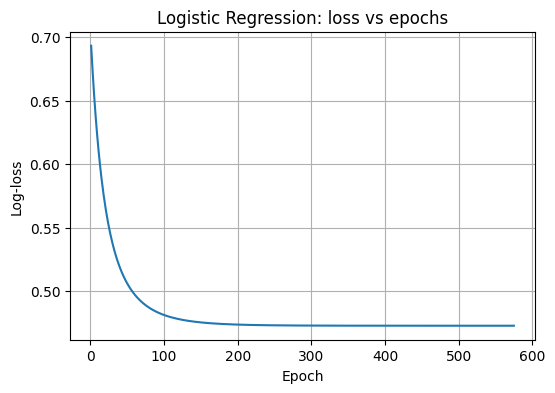

In [8]:

# ---------- Results ----------
print("\n--- Perceptron ---")
print("Weights (Glucose, BMI):", w_p.round(4))
print("Bias:", round(b_p, 4))
print("First 5 test predictions:", pred_p[:5])

print("\n--- Logistic Regression ---")
print("Weights (Glucose, BMI):", w_l.round(4))
print("Bias:", round(b_l, 4))
print("First 5 test predictions:", pred_l[:5])
print("First 5 P(class=1):", prob_l[:5].round(4))

# ---------- Loss curve ----------
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(losses) + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Log-loss")
plt.title("Logistic Regression: loss vs epochs")
plt.grid(True)
plt.show()

## Task 3 — Implement both using libraries
- Train `sklearn.linear_model.Perceptron` and `sklearn.linear_model.LogisticRegression` using exactly the same prepared training and test data.
- Use consistent random_state settings.
- Plot all four decision boundaries (scratch and library implementations) using the two chosen predictors.
- Describe how the boundaries differ and why exact coefficients may differ across implementations.

In [9]:
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import accuracy_score

# ---------- Library models (same X_train_s, y_train, X_test_s, y_test) ----------
sk_per = Perceptron(max_iter=1000, tol=1e-3, random_state=42)
sk_log = LogisticRegression(random_state=42)

sk_per.fit(X_train_s, y_train)
sk_log.fit(X_train_s, y_train)

# ---------- Coefficients and accuracy ----------
models = {
    "Perceptron (scratch)":  (w_p, b_p),
    "Perceptron (sklearn)":  (sk_per.coef_[0], sk_per.intercept_[0]),
    "LogReg (scratch)":      (w_l, b_l),
    "LogReg (sklearn)":      (sk_log.coef_[0], sk_log.intercept_[0]),
}

for name, (w, b) in models.items():
    pred = ((X_test_s @ w + b) >= 0).astype(int)
    print(f"{name:22s} w={w.round(3)}  b={b:.3f}  test acc={accuracy_score(y_test, pred):.3f}")


Perceptron (scratch)   w=[0.09  0.044]  b=-0.000  test acc=0.701
Perceptron (sklearn)   w=[ 2.035 -2.684]  b=0.000  test acc=0.539
LogReg (scratch)       w=[1.247 0.665]  b=-0.836  test acc=0.727
LogReg (sklearn)       w=[1.231 0.657]  b=-0.834  test acc=0.727


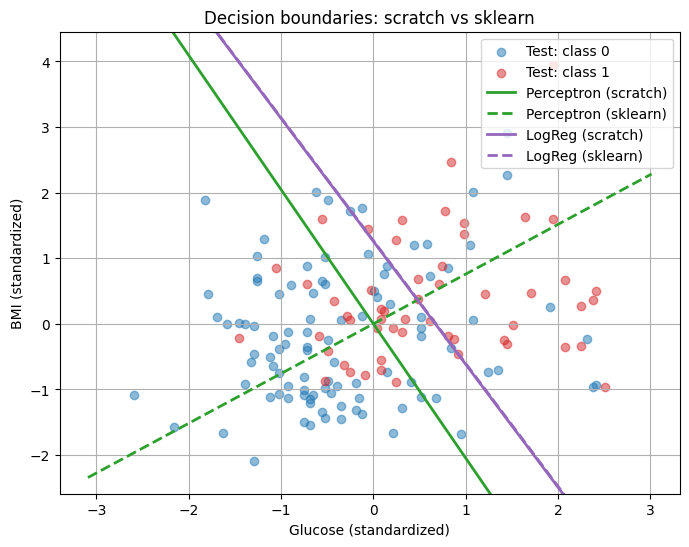

In [10]:
# ---------- Decision boundaries ----------
# Boundary: w1*x1 + w2*x2 + b = 0  ->  x2 = -(w1*x1 + b) / w2
x1 = np.linspace(X_test_s[:, 0].min() - 0.5, X_test_s[:, 0].max() + 0.5, 200)

plt.figure(figsize=(8, 6))
plt.scatter(X_test_s[y_test == 0, 0], X_test_s[y_test == 0, 1],
            c="tab:blue", alpha=0.5, label="Test: class 0")
plt.scatter(X_test_s[y_test == 1, 0], X_test_s[y_test == 1, 1],
            c="tab:red", alpha=0.5, label="Test: class 1")

styles = {
    "Perceptron (scratch)": ("tab:green",  "-"),
    "Perceptron (sklearn)": ("tab:green",  "--"),
    "LogReg (scratch)":     ("tab:purple", "-"),
    "LogReg (sklearn)":     ("tab:purple", "--"),
}
for name, (w, b) in models.items():
    color, ls = styles[name]
    x2 = -(w[0] * x1 + b) / w[1]
    plt.plot(x1, x2, color=color, linestyle=ls, linewidth=2, label=name)

plt.ylim(X_test_s[:, 1].min() - 0.5, X_test_s[:, 1].max() + 0.5)
plt.xlabel("Glucose (standardized)")
plt.ylabel("BMI (standardized)")
plt.title("Decision boundaries: scratch vs sklearn")
plt.legend()
plt.grid(True)
plt.show()

- The two Logistic Regression boundaries almost overlap because both minimize the same convex log-loss
- the Perceptron boundaries differ from them and from each other because the data is not linearly separable,
- so their final $w$ and $b$ depend on update order, learning rate and stopping rule; exact coefficients differ across implementations because of shuffling, learning rate, L2 regularization (`C=1.0`) in `sklearn` and the solver (`lbfgs` vs batch gradient descent).

## Task 4 — Evaluate and explain
- For all four models, calculate confusion matrix, accuracy, precision, recall and F1 on the held-out test set.
- Implement metrics manually for at least one model and verify against scikit-learn. Present a compact
comparison table.
- Identify the preferable model if missing a positive screening case is more costly than raising a false alarm, and support your choice using recall and the confusion matrix.
- Do not select a model solely from test accuracy.

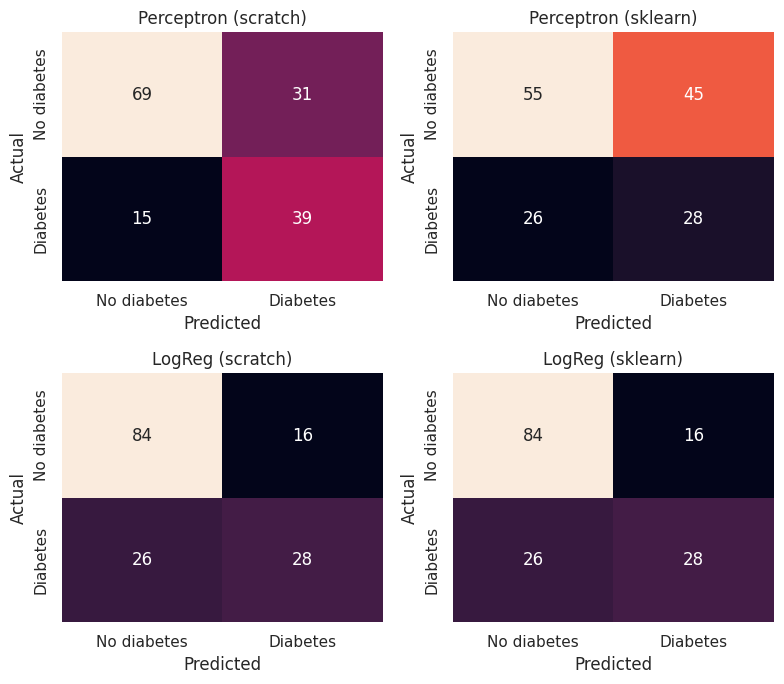

In [17]:
import seaborn as sns

# ---------- 1. Confusion matrices ----------
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, (name, pred) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(yt, pred), annot=True, fmt="d", cbar=False, ax=ax,
                xticklabels=["No diabetes", "Diabetes"],
                yticklabels=["No diabetes", "Diabetes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


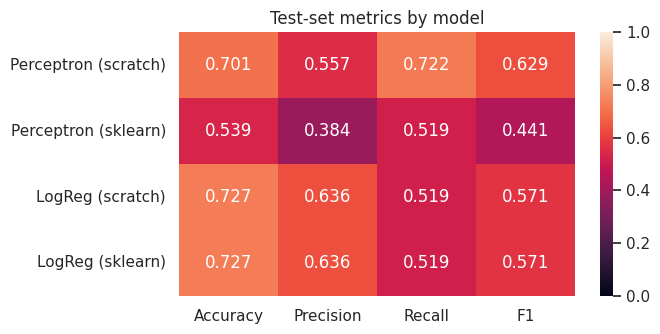

In [18]:
# ---------- 2. Metrics heatmap ----------
plt.figure(figsize=(7, 3.5))
sns.heatmap(table[["Accuracy", "Precision", "Recall", "F1"]],
            annot=True, fmt=".3f", vmin=0, vmax=1)
plt.title("Test-set metrics by model")
plt.ylabel("")
plt.tight_layout()
plt.show()

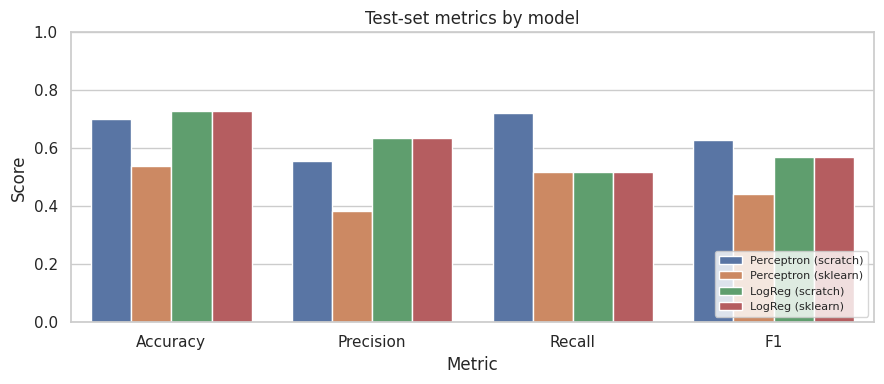

In [19]:
# ---------- 3. Grouped bar chart ----------
long = (table[["Accuracy", "Precision", "Recall", "F1"]]
        .reset_index()
        .melt(id_vars="Model", var_name="Metric", value_name="Score"))

plt.figure(figsize=(9, 4))
sns.barplot(data=long, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1)
plt.title("Test-set metrics by model")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()